# 03. Regression Analysis

The dependent variable is `log_price`. A coefficient β means that a one-unit increase in that variable changes price by about `(e^β − 1) × 100` percent.

| Model | Formula | Purpose |
|---|---|---|
| M1 | log_price ~ mileage | Mileage only |
| M2 | log_price ~ age | Age only |
| M3 | log_price ~ mileage + age | Both (collinear) |
| M4 | log_price ~ mileage + age + brand | Control for brand |
| **M5** | **log_price ~ annual_mileage + age + brand** | **Final: total mileage → annual mileage** |
| M6 | M5 + transmission + fuel + engine size + car model | Robustness check |

Standard errors are heteroskedasticity-robust (HC3).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from features import load_raw, clean, pct_effect, PROCESSED_DIR, ROOT
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
df = pd.read_csv(PROCESSED_DIR / "cars_clean.csv")
formulas = {
    "M1": "log_price ~ mileage_k",
    "M2": "log_price ~ age",
    "M3": "log_price ~ mileage_k + age",
    "M4": "log_price ~ mileage_k + age + C(brand)",
    "M5": "log_price ~ annual_mileage_k + age + C(brand)",
    "M6": "log_price ~ annual_mileage_k + age + C(model) + C(transmission) + C(fuelType) + engineSize",
}
models = {k: smf.ols(f, data=df).fit(cov_type="HC3") for k, f in formulas.items()}

In [3]:
rows = []
for name, m in models.items():
    r = {"model": name, "R2": m.rsquared, "N": int(m.nobs)}
    for v in ["mileage_k", "annual_mileage_k", "age"]:
        if v in m.params:
            r[v] = f"{m.params[v]:.4f} ({m.bse[v]:.4f})"
            r[v + " %"] = round(pct_effect(m.params[v]), 2)
    rows.append(r)
summary = pd.DataFrame(rows).set_index("model")
summary.to_csv(ROOT / "figures" / "regression_summary.csv")
summary

,R2,N,mileage_k,mileage_k %,age,age %,annual_mileage_k,annual_mileage_k %
model,,,,,,,,
M1,0.235,96255,-0.0124 (0.0001),-1.230,NaN,NaN,NaN,NaN
M2,0.361,96255,NaN,NaN,-0.1533 (0.0009),-14.210,NaN,NaN
M3,0.363,96255,-0.0020 (0.0001),-0.200,-0.1386 (0.0014),-12.940,NaN,NaN
M4,0.676,96255,-0.0038 (0.0001),-0.380,-0.1202 (0.0010),-11.320,NaN,NaN
M5,0.674,96255,NaN,NaN,-0.1456 (0.0007),-13.550,-0.0106 (0.0002),-1.060
M6,0.938,96255,NaN,NaN,-0.1354 (0.0004),-12.670,-0.0154 (0.0001),-1.530


Numbers in parentheses are HC3 standard errors. The `%` columns give the percent change in price for a one-unit increase (1,000 miles for mileage, one year for age).

In [4]:
print(models["M5"].summary().tables[1].as_text()[:2500])

                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 10.4203      0.004   2955.281      0.000      10.413      10.427
C(brand)[T.BMW]           -0.0082      0.004     -2.073      0.038      -0.016      -0.000
C(brand)[T.Ford]          -0.5424      0.003   -158.482      0.000      -0.549      -0.536
C(brand)[T.Hyundai]       -0.5698      0.006   -100.993      0.000      -0.581      -0.559
C(brand)[T.Mercedes]       0.0614      0.004     16.662      0.000       0.054       0.069
C(brand)[T.Skoda]         -0.5060      0.005   -101.148      0.000      -0.516      -0.496
C(brand)[T.Toyota]        -0.5471      0.006    -96.211      0.000      -0.558      -0.536
C(brand)[T.Vauxhall]      -0.7058      0.003   -206.592      0.000      -0.713      -0.699
C(brand)[T.Volkswagen]    -0.3134      0.004    -80.655      0.000      -0.321      -0.306

## Multicollinearity diagnostic (VIF)

The variance inflation factor (VIF) measures how well a variable is explained by the other explanatory variables. The higher it is, the less stable that variable's coefficient estimate. Values above 5 or 10 are commonly treated as serious.

In [5]:
def vif_table(cols):
    X = df[cols].assign(const=1.0).values
    return pd.Series([variance_inflation_factor(X, i) for i in range(len(cols))], index=cols)

pd.DataFrame({"total mileage + age (M3)": vif_table(["mileage_k", "age"]).values,
              "annual mileage + age (M5)": vif_table(["annual_mileage_k", "age"]).values},
             index=["mileage variable", "age"])

,total mileage + age (M3),annual mileage + age (M5)
mileage variable,2.305,1.020
age,2.305,1.020


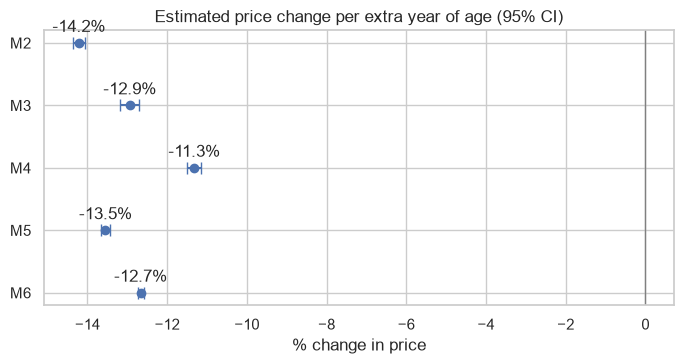

In [6]:
est = pd.DataFrame({
    "model": list(models),
    "age_pct": [pct_effect(m.params.get("age", np.nan)) for m in models.values()],
    "lo": [pct_effect(m.conf_int().loc["age", 0]) if "age" in m.params else np.nan for m in models.values()],
    "hi": [pct_effect(m.conf_int().loc["age", 1]) if "age" in m.params else np.nan for m in models.values()],
}).dropna()
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar(est["age_pct"], est["model"], xerr=[est["age_pct"] - est["lo"], est["hi"] - est["age_pct"]],
            fmt="o", color="#4C72B0", capsize=4)
for _, r in est.iterrows():
    ax.annotate(f"{r.age_pct:.1f}%", (r.age_pct, r.model), textcoords="offset points", xytext=(0, 8), ha="center")
ax.axvline(0, color="grey", lw=1)
ax.invert_yaxis()
ax.set(title="Estimated price change per extra year of age (95% CI)", xlabel="% change in price")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_age_effect_by_model.png", dpi=150); plt.show()

## Age effect by brand

M5 is estimated separately for each brand, to check that the age effect is not driven by any single brand.

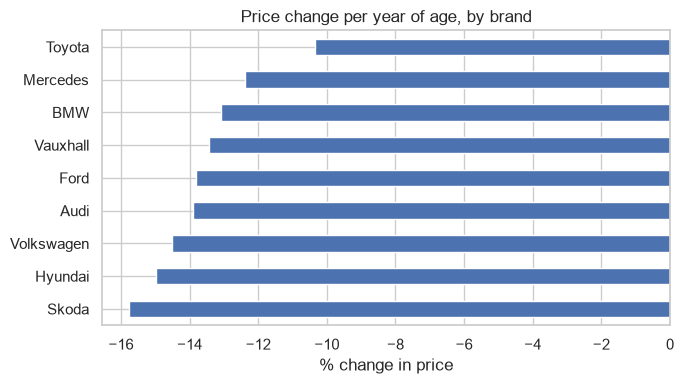

brand
Skoda        -15.800
Hyundai      -15.000
Volkswagen   -14.500
Audi         -13.900
Ford         -13.800
Vauxhall     -13.400
BMW          -13.100
Mercedes     -12.400
Toyota       -10.400
dtype: float64

In [7]:
by_brand = (df.groupby("brand")
              .apply(lambda d: pct_effect(smf.ols("log_price ~ annual_mileage_k + age", d).fit().params["age"]))
              .sort_values())
ax = by_brand.plot.barh(figsize=(7, 4), color="#4C72B0")
ax.set(title="Price change per year of age, by brand", xlabel="% change in price", ylabel="")
plt.tight_layout(); plt.savefig(FIG_DIR / "05_age_effect_by_brand.png", dpi=150); plt.show()
by_brand.round(1)

## Interpretation

- **M1:** With mileage alone, the coefficient is negative: cars with more miles sell for less, as expected (−1.2% per 1,000 miles).
- **M3/M4:** Adding age makes the total-mileage effect shrink sharply, to −0.2% to −0.4% per 1,000 miles, because the two variables share overlapping information. In M1, mileage was also picking up part of the effect of age. The VIF is about 2.3, so the collinearity in this data is not *severe*, and the sign of the age coefficient never flips.
- **M5:** Replacing total mileage with annual mileage brings the VIF down to about 1.0 and cleanly separates the two effects. **Holding annual mileage and brand constant, each additional year of age lowers price by about 13.5%.**
- **M6 and by brand:** The result stays within 10–16% per year when controlling for car model, transmission, fuel type and engine size, and when each brand is estimated separately.

**Limitations:** This is observational data, so the estimates are conditional associations, not causal effects. There is no information on accident history, condition, options or region. The data covers the 2020 UK market and mostly cars aged 0–7 years, so it may not generalize to older cars or other markets.